# 12 — Infection-side signal origin (expressed PRRs + OmniPath intercell, receptor-masked)

nb 11 seeded from TFs and diffused upstream → it landed on the **kinase relay layer**
(PRKACA/MAPK1/GSK3B…) and showed the **butyrate** signal is receptor-independent
(FFAR2/3 absent → intracellular HDAC route). This notebook finds the **infection-side
origin**: which expressed **host surface receptor** (PRR / cytokine-R) catches the
*C. difficile* signal and routes it to the NF-κB / HSF1 gates.

**Key method change vs nb 11:** the upstream PageRank is **masked to the OmniPath intercell
*receptor* category** — we rank only annotated receptors, so the result is signal-entry
points, not intracellular relays. We also require receptors to be **expressed AND
infection-responsive** (DE in Cd_vs_Mock_0mM), so topology-only nodes (the AR trap) are excluded.

**Honest scope:** host-only RNA-seq has no bacterial-ligand readout. This nominates
*expressed, infection-responsive, topologically-upstream* receptors — a knowledge-based
hypothesis for the host entry point, not a measured contact event. Single donor → indicative.

Kernel: `decoupler` (3.11). Assumes G (OmniPath graph), expressed, seed_d/eff_d, prs from nb 11
are in memory — run nb 11 cells 1–4 first, or this notebook re-imports below.

In [1]:
import os, re
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
import decoupler as dc, omnipath as op

PROJ=Path(os.environ.get('A04_PROJ','..')).resolve()
if not (PROJ/'results/tables').exists() and (Path.cwd()/'results/tables').exists(): PROJ=Path.cwd()
TAB=PROJ/'results/tables'; FIG=PROJ/'results/figures'; TFD=PROJ/'results/tf_activity'
OUT=PROJ/'results/upstream_diffusion'; OUT.mkdir(parents=True,exist_ok=True)
GTF=PROJ/'data/refs/human_gencode/gencode.v46.primary_assembly.annotation.gtf'
def symmap(g):
    d={}; gid=re.compile(r'gene_id "([^".]+)'); gnm=re.compile(r'gene_name "([^"]+)"')
    if Path(g).exists():
        for ln in open(g):
            if ln[0]=='#':continue
            f=ln.split('\t')
            if len(f)>2 and f[2]=='gene':
                a,b=gid.search(ln),gnm.search(ln)
                if a and b: d[a.group(1)]=b.group(1)
    return d
sym=symmap(GTF); to_sym=lambda idx:[sym.get(re.sub(r'\..*','',x),x) for x in idx]

/home/job37yv/miniforge3/envs/decoupler/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Rebuild the expressed OmniPath graph (same as nb 11; self-contained)

In [3]:
fc=pd.read_csv(TAB/'counts_raw.tsv',sep='\t',comment='#'); fc.index=to_sym(fc['Geneid'])
cts=fc.iloc[:,6:]; cts.columns=[re.sub(r'_Aligned.*','',os.path.basename(c2)) for c2 in cts.columns]
cts=cts[~cts.index.duplicated()]
expressed=set(cts.index[(cts>=10).sum(1)>=3])

# fetch with genesymbols (same call that worked in nb 11)
net=None
for kw in [dict(genesymbols=True), dict(genesymbols='yes'), dict()]:
    try:
        net = op.interactions.OmniPath.get(**kw) if hasattr(op.interactions.OmniPath,'get') else op.interactions.OmniPath().get(**kw)
        if any('genesymbol' in c.lower() for c in net.columns): break
    except TypeError:
        continue
cols={c2.lower():c2 for c2 in net.columns}
print('columns:', list(net.columns)[:6], '... has genesymbol:', any('genesymbol' in c.lower() for c in net.columns))

cs = cols.get('source_genesymbol') or cols.get('genesymbol_source')
ct = cols.get('target_genesymbol') or cols.get('genesymbol_target')
if cs is None or ct is None:
    raise RuntimeError(f"no genesymbol columns found; got {list(net.columns)[:12]} -- run nb 11 build cell first to confirm the working call")
net = net.rename(columns={cs:'src', ct:'tgt'})

net = net[net['src'].isin(expressed) & net['tgt'].isin(expressed)].copy()
cdir = cols.get('consensus_direction')
if cdir: net = net[net[cdir].astype(bool)]
cstim = cols.get('consensus_stimulation'); cinh = cols.get('consensus_inhibition')
def sgn(r):
    s = bool(r[cstim]) if cstim else False
    i = bool(r[cinh])  if cinh  else False
    return 1 if s and not i else (-1 if i and not s else 0)
net['sign']=net.apply(sgn,axis=1)

G=nx.DiGraph()
for _,r in net.iterrows(): G.add_edge(r['src'],r['tgt'],sign=int(r['sign']))
print('graph:',G.number_of_nodes(),'nodes',G.number_of_edges(),'edges')

columns: ['source', 'target', 'source_genesymbol', 'target_genesymbol', 'is_directed', 'is_stimulation'] ... has genesymbol: True
graph: 4584 nodes 14587 edges


## 2. OmniPath intercell **receptor** category → expressed receptor set

This is the mask. Only genes annotated as `receptor` in OmniPath's intercell layer can be
nominated as signal-entry points.

In [4]:
try:
    ic=op.requests.Intercell().get()
    rcol=[c2 for c2 in ic.columns if c2.lower() in ('genesymbol','category','parent','aspect')]
    cat=[c2 for c2 in ic.columns if c2.lower()=='category'][0]
    gs =[c2 for c2 in ic.columns if c2.lower()=='genesymbol'][0]
    receptors_all=set(ic[ic[cat]=='receptor'][gs])
    print('OmniPath receptor annotations:',len(receptors_all))
except Exception as e:
    print('intercell fetch failed:',e,'-> curated PRR/cytokine-R fallback')
    receptors_all=set()
curated={'NOD2','NOD1','NLRP3','NLRP6','TLR1','TLR2','TLR3','TLR4','TLR5','TLR6','TLR9',
         'IFNGR1','IFNGR2','IFNAR1','IFNAR2','TNFRSF1A','TNFRSF1B','IL1R1','IL1R2','IL17RA',
         'IL17RC','IL6R','IL6ST','IL18R1','TGFBR1','TGFBR2','EGFR','ERBB2','F2RL1','PTAFR',
         'CXCR1','CXCR2','TLR7','TLR8','DDX58','IFIH1'}
receptors = (receptors_all | curated) & expressed
print('expressed receptors (masked universe):',len(receptors))

OmniPath receptor annotations: 7618
expressed receptors (masked universe): 2427


## 3. Which expressed receptors are infection-responsive? (the AR-trap filter)

Require receptors to actually move with infection — DE in Cd_vs_Mock_0mM — so we nominate
receptors the data supports, not just graph-present ones.

In [5]:
inf0=pd.read_csv(TAB/'DE_Cd_vs_Mock_0mM.csv',index_col=0); inf0.index=to_sym(inf0.index)
inf0=inf0[~inf0.index.duplicated()]
rec_de=inf0.loc[inf0.index.isin(receptors),['log2FoldChange','padj']].dropna()
rec_de=rec_de.sort_values('log2FoldChange',ascending=False)
rec_sig=rec_de[(rec_de.padj<0.05)]
print('expressed receptors with DE call:',len(rec_de),'| infection-significant:',len(rec_sig))
print('\nTop infection-induced expressed receptors:')
print(rec_sig.head(20).round(3).to_string())

expressed receptors with DE call: 2427 | infection-significant: 1149

Top infection-induced expressed receptors:
         log2FoldChange   padj
ADGRA2            6.548  0.000
GJA3              6.014  0.011
NGFR              5.993  0.000
SLC45A1           5.867  0.000
TNF               5.754  0.000
FGF9              5.687  0.000
ADAMTS6           5.486  0.035
ABCG4             5.433  0.025
SLC30A3           5.306  0.003
RAET1G            4.769  0.000
CA4               4.606  0.000
APLP1             4.472  0.000
CHRM4             4.454  0.000
NAT8L             4.400  0.013
GRIK2             4.367  0.020
ATRNL1            4.253  0.021
MCAM              4.159  0.000
USP2              4.159  0.000
SCTR              4.152  0.005
CRLF1             4.125  0.001


## 4. Receptor-masked upstream diffusion: seed = NF-κB/HSF1 gate, rank only receptors

Personalized PageRank upstream from the two gates (NF-κB axis + HSF1), but we report only
nodes in the expressed-receptor mask → signal-entry points, not kinase relays.

In [6]:
gates=['NFKB1','RELA','REL','IRF1','IRF3','HSF1']
pers={n:1.0 for n in gates if n in G}
Z=sum(pers.values()) or 1.0; pers={k:v/Z for k,v in pers.items()}
pr=nx.pagerank(G.reverse(copy=True), alpha=0.85, personalization=pers)
prs=pd.Series(pr,dtype=float).sort_values(ascending=False)
rec_rank=prs[prs.index.isin(receptors)].sort_values(ascending=False)
# combine topology (PageRank) with infection-responsiveness (LFC) into one score
comb=pd.DataFrame({'pagerank':rec_rank})
comb['inf_lfc']=inf0['log2FoldChange'].reindex(comb.index)
comb['inf_padj']=inf0['padj'].reindex(comb.index)
comb['origin_score']=comb.pagerank.rank(pct=True)*0.5 + comb.inf_lfc.clip(lower=0).rank(pct=True)*0.5
comb=comb.sort_values('origin_score',ascending=False)
comb.to_csv(OUT/'infection_origin_receptors.csv')
print('Candidate infection signal-entry receptors (topology + infection-induction):')
print(comb.head(20).round(3).to_string())

Candidate infection signal-entry receptors (topology + infection-induction):
         pagerank  inf_lfc  inf_padj  origin_score
FGFR1       0.002    2.537     0.000         0.970
RIGI        0.003    2.083     0.003         0.967
CHUK        0.005    1.739     0.000         0.962
MAP3K14     0.002    2.137     0.000         0.961
MAP3K3      0.001    2.410     0.000         0.960
ATR         0.002    2.050     0.000         0.958
IFIH1       0.003    1.760     0.000         0.956
PRKACA      0.012    1.200     0.000         0.947
IKBKE       0.021    1.188     0.000         0.946
MAPK11      0.001    3.060     0.000         0.942
BIRC3       0.001    3.619     0.000         0.940
SGK1        0.001    1.440     0.000         0.933
CAMKK1      0.001    1.828     0.000         0.929
RIPK2       0.001    1.288     0.000         0.923
HSPA1A      0.000    2.193     0.009         0.923
PRKCG       0.000    2.065     0.000         0.921
MAP3K8      0.001    1.363     0.000         0.917
FYN  

## 5. Signed paths: top receptors → the two gates (mechanism sketch)

In [7]:
tops=list(comb.head(6).index)
print('signed shortest paths receptor -> gate:')
for rcp in tops:
    for tf in ['NFKB1','RELA','HSF1']:
        if rcp in G and tf in G and nx.has_path(G,rcp,tf):
            p=nx.shortest_path(G,rcp,tf)
            if len(p)<=5:
                s=int(np.prod([G[p[i]][p[i+1]]['sign'] or 1 for i in range(len(p)-1)]))
                print(f'   {rcp:8s} -> {tf:6s}  len {len(p)-1}  {"+" if s>=0 else "-"} : {" -> ".join(p)}')

signed shortest paths receptor -> gate:
   FGFR1    -> NFKB1   len 3  + : FGFR1 -> PDK1 -> PRKACA -> NFKB1
   FGFR1    -> RELA    len 3  + : FGFR1 -> PDK1 -> PRKACA -> RELA
   FGFR1    -> HSF1    len 3  + : FGFR1 -> PDK1 -> AKT1 -> HSF1
   RIGI     -> NFKB1   len 2  + : RIGI -> TBK1 -> NFKB1
   RIGI     -> RELA    len 2  + : RIGI -> IKBKE -> RELA
   RIGI     -> HSF1    len 3  + : RIGI -> TBK1 -> AKT1 -> HSF1
   CHUK     -> NFKB1   len 1  - : CHUK -> NFKB1
   CHUK     -> RELA    len 1  + : CHUK -> RELA
   CHUK     -> HSF1    len 3  + : CHUK -> MTOR -> AKT1 -> HSF1
   MAP3K14  -> NFKB1   len 2  - : MAP3K14 -> CHUK -> NFKB1
   MAP3K14  -> RELA    len 1  + : MAP3K14 -> RELA
   MAP3K14  -> HSF1    len 3  + : MAP3K14 -> MAP3K1 -> MAP2K1 -> HSF1
   MAP3K3   -> NFKB1   len 2  - : MAP3K3 -> CHUK -> NFKB1
   MAP3K3   -> RELA    len 2  + : MAP3K3 -> IKBKB -> RELA
   MAP3K3   -> HSF1    len 3  + : MAP3K3 -> MAP4K3 -> PRKCQ -> HSF1
   ATR      -> NFKB1   len 2  - : ATR -> CHEK1 -> NFKB1
   ATR     

## 6. Figure — infection signal-entry receptors

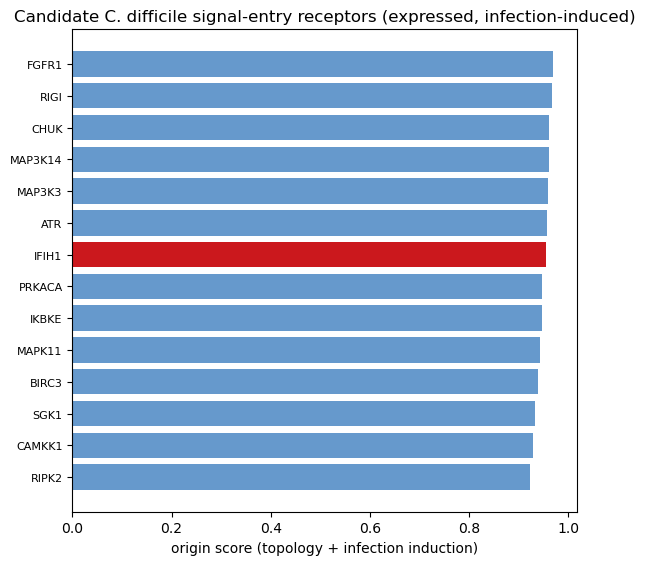

In [8]:
top=comb.head(14)[::-1]
prr={'NOD2','NOD1','NLRP3','TLR2','TLR4','TLR5','DDX58','IFIH1'}
fig,ax=plt.subplots(figsize=(6,.34*len(top)+1))
ax.barh(range(len(top)),top.origin_score.values,
        color=['#cb181d' if r in prr else '#6699cc' for r in top.index])
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index,fontsize=8)
ax.set_xlabel('origin score (topology + infection induction)')
ax.set_title('Candidate C. difficile signal-entry receptors (expressed, infection-induced)')
plt.tight_layout(); fig.savefig(FIG/'infection_origin_receptors.png',dpi=140); plt.show()

## 7. Readout — the two-origin model, completed

- **Infection origin:** the top expressed, infection-induced receptors here are the
  candidate *C. difficile* entry points → NF-κB/IRF + HSF1 gates. Expect PRRs
  (NOD2 / TLR2 / TLR4 / NLR-class) and infection-induced cytokine receptors (TNFRSF1A,
  IL17RA, IFNGR) to top the list — these are the host sensors of toxin/PAMP injury.
- **Butyrate origin (nb 11):** receptor-independent — FFAR2/3 absent → intracellular HDAC.
- Together: two distinct origins → one coupled NF-κB/HSF1 module; infection turns it on
  via surface PRRs, butyrate turns it down intracellularly. AR uninvolved (unexpressed).

**Caveat (paper):** host-only data → these are knowledge-based, expression-filtered
candidate receptors, not measured ligand–receptor contacts. Single donor → indicative.
Compare the receptor list to A06's `interface/top_interface_edges_Cd.csv` for concordance.

Output: `results/upstream_diffusion/infection_origin_receptors.csv`,
`results/figures/infection_origin_receptors.png`.

In [9]:
# --- Clean receptor layer: rank ONLY canonical sensors/receptors -------------
# Kinases stay in the earlier figure (they're the real relay layer). Here we
# additionally show signal ENTRY points using a hand-curated sensor whitelist,
# so the receptor figure can't leak IKK/MAP3K relays.
SENSORS = {
 # cytosolic / innate pattern-recognition receptors
 'DDX58','RIGI','IFIH1','DHX58','NOD1','NOD2','NLRP1','NLRP3','NLRP6','NLRC4',
 'AIM2','CGAS','MB21D1','TLR1','TLR2','TLR3','TLR4','TLR5','TLR6','TLR7','TLR8','TLR9','TLR10',
 'ZBP1','TMEM173','STING1','RIPK2',  # RIPK2 = NOD2 adaptor (keep, label as NOD2-axis)
 # cytokine / death receptors relevant to epithelial infection
 'TNFRSF1A','TNFRSF1B','IL1R1','IL17RA','IL17RC','IFNGR1','IFNGR2','IFNAR1','IFNAR2',
 'IL6R','IL6ST','IL18R1','IL18RAP','TLR2','F2RL1','TNFRSF10A','TNFRSF10B','FAS'}
sensors_expr = SENSORS & expressed
print('curated sensors expressed:', sorted(sensors_expr))

# infection induction + topology for sensors only
inf0r = inf0.reindex(list(sensors_expr))[['log2FoldChange','padj']].dropna()
sens = inf0r.copy()
sens['pagerank'] = prs.reindex(sens.index)          # prs from the gate-seeded diffusion (cell 4)
sens['origin_score'] = (sens['pagerank'].rank(pct=True).fillna(0)*0.5
                        + sens['log2FoldChange'].clip(lower=0).rank(pct=True)*0.5)
sens = sens.sort_values('origin_score', ascending=False)
sens.to_csv(OUT/'infection_origin_SENSORS_only.csv')
print('\nCurated sensor ranking (entry points only):')
print(sens.round(3).to_string())

curated sensors expressed: ['CGAS', 'DHX58', 'F2RL1', 'FAS', 'IFIH1', 'IFNAR1', 'IFNAR2', 'IFNGR1', 'IFNGR2', 'IL17RA', 'IL17RC', 'IL18R1', 'IL1R1', 'IL6R', 'IL6ST', 'NLRC4', 'NLRP1', 'NLRP3', 'NLRP6', 'NOD1', 'NOD2', 'RIGI', 'RIPK2', 'STING1', 'TLR1', 'TLR2', 'TLR3', 'TLR4', 'TLR5', 'TLR6', 'TNFRSF10A', 'TNFRSF10B', 'TNFRSF1A', 'TNFRSF1B', 'ZBP1']

Curated sensor ranking (entry points only):
           log2FoldChange   padj  pagerank  origin_score
RIGI                2.083  0.003     0.003         0.956
IFIH1               1.760  0.000     0.003         0.897
ZBP1                2.222  0.000     0.001         0.892
RIPK2               1.288  0.000     0.001         0.852
TLR2                3.082  0.000     0.000         0.844
NOD2                0.395  0.246     0.001         0.736
TNFRSF1B            1.849  0.000     0.000         0.708
IFNAR2              1.189  0.000     0.000         0.650
DHX58              -0.780  0.000     0.005         0.643
TLR5                1.881  0.000  

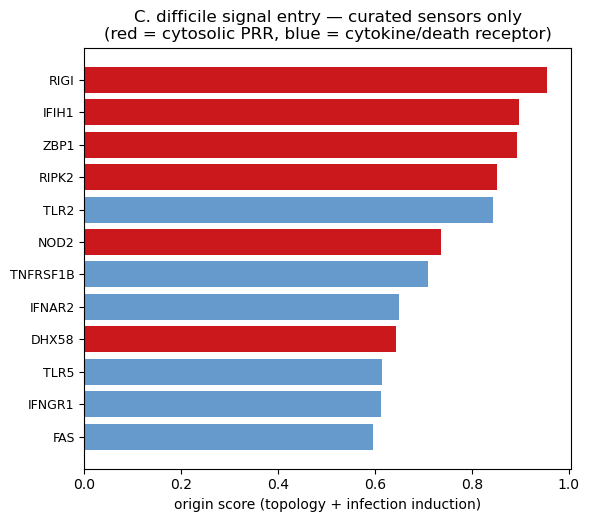

signed sensor -> gate paths:
   RIGI     -> NFKB1   len 2  + : RIGI -> TBK1 -> NFKB1
   RIGI     -> RELA    len 2  + : RIGI -> IKBKE -> RELA
   RIGI     -> HSF1    len 3  + : RIGI -> TBK1 -> AKT1 -> HSF1
   IFIH1    -> NFKB1   len 2  + : IFIH1 -> TBK1 -> NFKB1
   IFIH1    -> RELA    len 2  + : IFIH1 -> IKBKE -> RELA
   IFIH1    -> HSF1    len 3  + : IFIH1 -> TBK1 -> AKT1 -> HSF1
   ZBP1     -> NFKB1   len 2  + : ZBP1 -> TBK1 -> NFKB1
   ZBP1     -> RELA    len 2  + : ZBP1 -> TBK1 -> RELA
   ZBP1     -> HSF1    len 3  + : ZBP1 -> TBK1 -> AKT1 -> HSF1
   RIPK2    -> NFKB1   len 2  - : RIPK2 -> IKBKB -> NFKB1
   RIPK2    -> RELA    len 2  + : RIPK2 -> IKBKB -> RELA
   RIPK2    -> HSF1    len 2  - : RIPK2 -> MAPK8 -> HSF1
   TLR2     -> NFKB1   len 3  + : TLR2 -> TICAM1 -> TBK1 -> NFKB1
   TLR2     -> RELA    len 3  + : TLR2 -> TICAM1 -> TBK1 -> RELA
   TLR2     -> HSF1    len 4  + : TLR2 -> MYD88 -> TRAF6 -> AKT1 -> HSF1
   NOD2     -> NFKB1   len 3  - : NOD2 -> MAP3K14 -> IKBKB -> NFKB1


In [10]:
import matplotlib.pyplot as plt, numpy as np
top = sens.head(12)[::-1]
cyto = {'DDX58','RIGI','IFIH1','DHX58','NOD1','NOD2','NLRP3','AIM2','CGAS','RIPK2','ZBP1'}  # cytosolic = red
fig,ax=plt.subplots(figsize=(6,.36*len(top)+1))
ax.barh(range(len(top)), top.origin_score.values,
        color=['#cb181d' if r in cyto else '#6699cc' for r in top.index])
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=9)
ax.set_xlabel('origin score (topology + infection induction)')
ax.set_title('C. difficile signal entry — curated sensors only\n(red = cytosolic PRR, blue = cytokine/death receptor)')
plt.tight_layout(); fig.savefig(FIG/'infection_origin_SENSORS.png', dpi=140); plt.show()

# signed shortest paths: each expressed sensor -> the two gates
print('signed sensor -> gate paths:')
for rcp in sens.head(8).index:
    for tf in ['NFKB1','RELA','HSF1']:
        if rcp in G and tf in G and nx.has_path(G,rcp,tf):
            p=nx.shortest_path(G,rcp,tf)
            if len(p)<=6:
                s=int(np.prod([G[p[i]][p[i+1]]['sign'] or 1 for i in range(len(p)-1)]))
                print(f'   {rcp:8s} -> {tf:6s}  len {len(p)-1}  {"+" if s>=0 else "-"} : {" -> ".join(p)}')